# psfcal on ESPRESSO: PSF of a laser-frequency-comb exposure

Same method as `harps_lfc_real_data.ipynb`, applied to a **different spectrograph**: nothing in psfcal is HARPS-specific.
We use three chunks of one ESPRESSO LFC exposure and look at what the method shows: a PSF of similar width to HARPS in pixels, sparser comb lines, and a PSF that **changes along the order**.

**Data.** `data/espresso_lfc_chunks.npz` holds three 400-pixel chunks (detector pixels 1000–1400, 4300–4700, 7600–8000) of spectral row 100 (of 170) of the ESO-archive exposure `r.ESPRE.2019-08-31T17:03:27.302_S2D_LFC_FP_A` (SINGLEUHR mode, fibre A, 40 s): flux and error arrays of the S2D product.
Fits are cached in `data/espresso_lfc_fit_cache.pkl`; set `RECOMPUTE = True` to redo them (~1 min each).

Contents: 1. data · 2. fit · 3. the PSF · 4. PSF along the order · 5. ESPRESSO vs HARPS · 6. background · 7. deconvolution

In [1]:
import pickle, time, warnings
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

import psfcal
from psfcal import plotting

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})

RECOMPUTE = False
DATA = Path("data")
CACHE = DATA / "espresso_lfc_fit_cache.pkl"

d = np.load(DATA / "espresso_lfc_chunks.npz")
X, FLUX, ERR = d["x"], d["flux"], d["err"]
print(str(d["info"]))
print("chunks:", X.shape, " peak flux per chunk:", [f"{f.max():.0f}" for f in FLUX])

ESPRESSO LFC exposure r.ESPRE.2019-08-31T17:03:27.302_S2D_LFC_FP_A (ESO archive, SINGLEUHR mode, fibre A, 40 s), spectral row 100 (0-based) of 170, three 400-pixel chunks starting at detector pixels 1000, 4300, 7600
chunks: (3, 400)  peak flux per chunk: ['175539', '219278', '237000']


## 1. The data

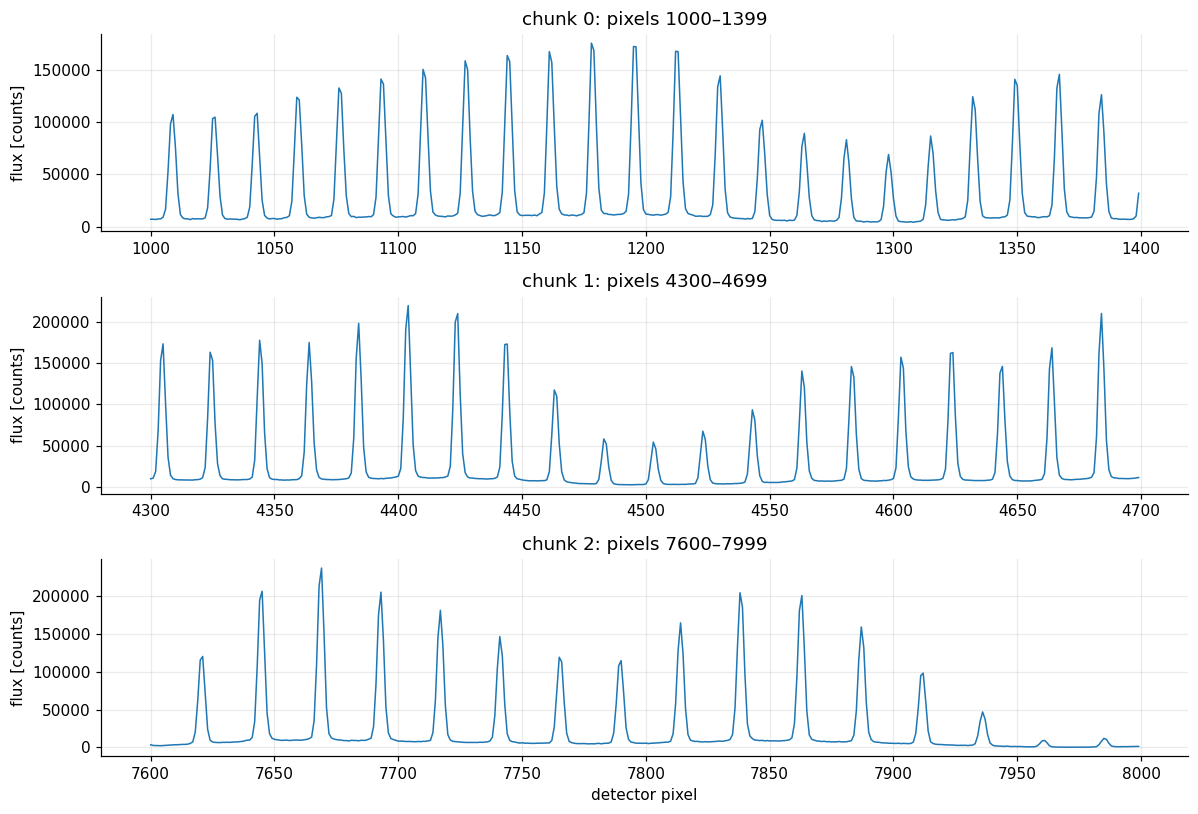

In [2]:
fig, axs = plt.subplots(3, 1, figsize=(11, 7.5))
for ax, x, f, i in zip(axs, X, FLUX, range(3)):
    ax.plot(x, f, lw=1)
    ax.set(ylabel="flux [counts]", title=f"chunk {i}: pixels {int(x[0])}–{int(x[-1])}")
axs[-1].set_xlabel("detector pixel")
plt.tight_layout(); plt.show()

Compared with the HARPS chunk: the lines are further apart (17–24 pixels here against ~14), so a 400-pixel chunk holds ~15–25 lines, and they peak at ~2×10⁵ counts (HARPS: ~1.2×10⁵).
Line heights vary from line to line, which is fine: psfcal normalises every line before stacking.

## 2. Fit

In [3]:
def run_fit(i, subtract_background=True):
    r = psfcal.compute_psf_chunk_pixel(X[i], FLUX[i], ERR[i], subtract_background=subtract_background)
    o = {q: r[q] for q in ("psf_x", "psf_mean", "psf_std", "stacked_x", "stacked_y", "stacked_yerr",
                           "rms", "line_centres", "background")}
    o["psf_area_norm"] = r.get("psf_area_norm", 1.0)
    return o

if CACHE.exists() and not RECOMPUTE:
    fits_ = pickle.load(open(CACHE, "rb"))
else:
    fits_ = {}
    for i in range(3):
        t0 = time.time(); fits_[f"c{i}_bkg_on"] = run_fit(i, True); print(f"chunk {i}: {time.time() - t0:.0f}s")
    fits_["c1_bkg_off"] = run_fit(1, False)
    pickle.dump(fits_, open(CACHE, "wb"))

for i in range(3):
    r = fits_[f"c{i}_bkg_on"]
    print(f"chunk {i}: {len(r['line_centres'])} lines → {len(r['stacked_x'])} stacked points")

chunk 0: 25 lines → 382 stacked points
chunk 1: 19 lines → 395 stacked points
chunk 2: 15 lines → 361 stacked points


The call is the same as for HARPS:

```python
r = psfcal.compute_psf_chunk_pixel(x, flux, err, subtract_background=True)
```

## 3. The reconstructed PSF (middle chunk)

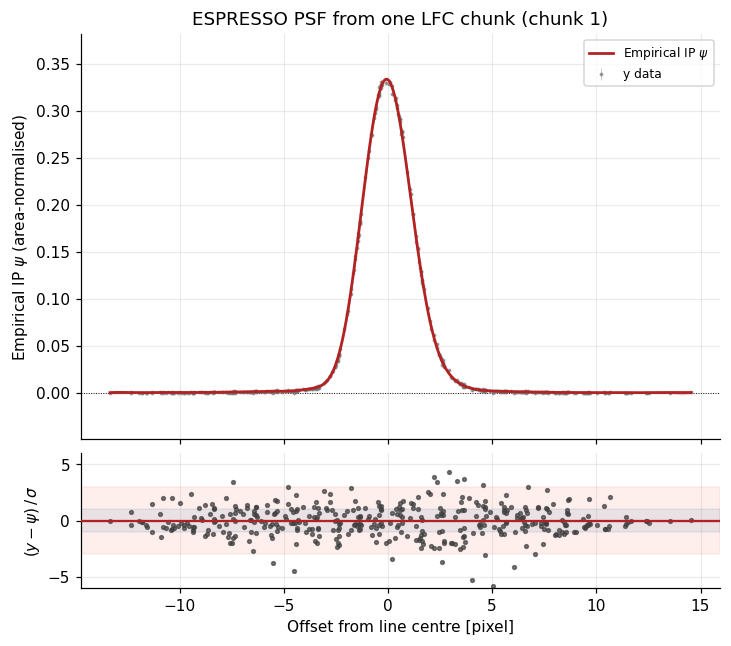

FWHM 2.72 px, skewness +0.00
stack residual 0.58% of the PSF peak  (photon error per stacked point: 0.57% of the peak)
full-chunk line-model RMS returned by psfcal: 23.0 sigma


In [4]:
good = fits_["c1_bkg_on"]
plotting.plot_psf(good, title="ESPRESSO PSF from one LFC chunk (chunk 1)", xlabel="Offset from line centre [pixel]")
plt.show()

def shape_stats(r):
    px, py = r["psf_x"], r["psf_mean"]
    inside = px[py >= py.max() / 2]
    fwhm = inside.max() - inside.min()
    m2 = np.trapz(px ** 2 * py, px)
    skew = np.trapz(px ** 3 * py, px) / m2 ** 1.5       # third standardised moment: 0 = symmetric
    sy = r["stacked_y"] / r["psf_area_norm"]
    res = sy - np.interp(r["stacked_x"], px, py)
    core = np.abs(r["stacked_x"]) < 4
    rel = 100 * np.sqrt(np.mean(res[core] ** 2)) / py.max()
    return fwhm, skew, rel
f_, s_, rel_ = shape_stats(good)
err_rel = 100 * np.median(good["stacked_yerr"][np.abs(good["stacked_x"]) < 2] / good["psf_area_norm"]) / good["psf_mean"].max()
print(f"FWHM {f_:.2f} px, skewness {s_:+.2f}")
print(f"stack residual {rel_:.2f}% of the PSF peak  (photon error per stacked point: {err_rel:.2f}% of the peak)")
print(f"full-chunk line-model RMS returned by psfcal: {good['rms']:.1f} sigma")

The fit follows the stack closely: the residuals of the stacked points (bottom panel) are at the level of the photon noise.
The `rms` value that psfcal returns is a different, stricter quantity: the residual of the **whole chunk** reconstructed from one PSF plus the fitted lines, in units of the photon error. Here it is ≈20σ (HARPS chunk: 2.9σ), i.e. the lines of this chunk differ from one another by more than photon noise. A plausible reason is that the PSF itself varies within a 400-pixel chunk (next section shows it varies along the order); shorter chunks would test this.

## 4. The PSF changes along the order

The three chunks come from the same exposure and the same row, a few thousand pixels apart.

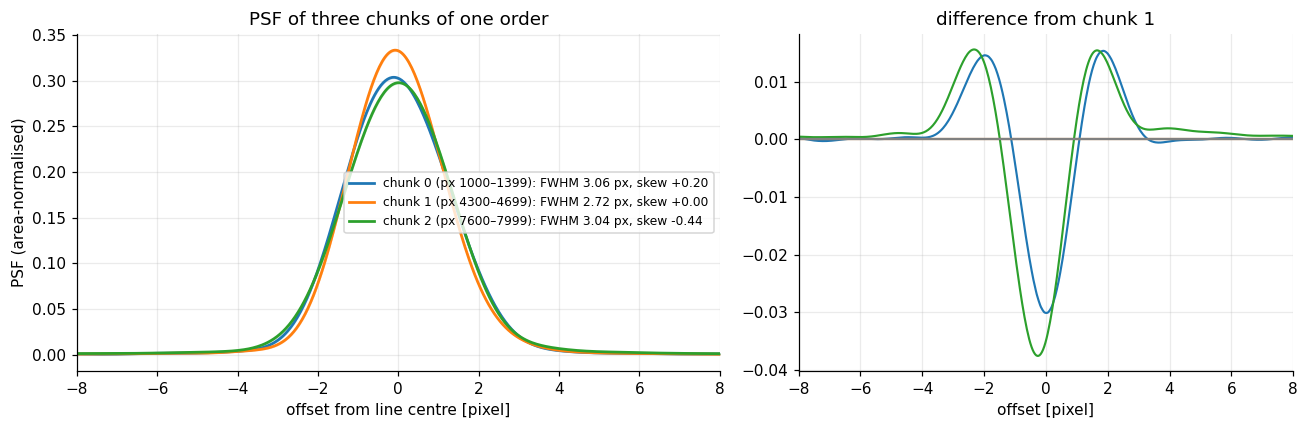

In [5]:
cols = ["tab:blue", "tab:orange", "tab:green"]
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw=dict(width_ratios=[1.3, 1]))
for i, col in enumerate(cols):
    r = fits_[f"c{i}_bkg_on"]
    f_, s_, _ = shape_stats(r)
    a.plot(r["psf_x"], r["psf_mean"], c=col, lw=1.8, label=f"chunk {i} (px {int(X[i][0])}–{int(X[i][-1])}): FWHM {f_:.2f} px, skew {s_:+.2f}")
    a.fill_between(r["psf_x"], r["psf_mean"] - r["psf_std"], r["psf_mean"] + r["psf_std"], color=col, alpha=0.2)
a.set(xlim=(-8, 8), xlabel="offset from line centre [pixel]", ylabel="PSF (area-normalised)", title="PSF of three chunks of one order")
a.legend(fontsize=8)
ref = fits_["c1_bkg_on"]
for i, col in enumerate(cols):
    r = fits_[f"c{i}_bkg_on"]
    b.plot(r["psf_x"], r["psf_mean"] - np.interp(r["psf_x"], ref["psf_x"], ref["psf_mean"]), c=col, lw=1.4)
b.axhline(0, c="0.5"); b.set(xlim=(-8, 8), xlabel="offset [pixel]", title="difference from chunk 1")
plt.tight_layout(); plt.show()

Both the width and the asymmetry differ between chunks (the skewness even changes sign), by far more than the statistical uncertainty (shaded).
This is why psfcal works **chunk by chunk** rather than assuming one PSF per order, and why the chunk length is a trade-off (see `parameters.ipynb`, section 3).

## 5. ESPRESSO versus HARPS (in detector pixels)

The two spectrographs have different pixel scales, so only the shapes in pixels are compared here.

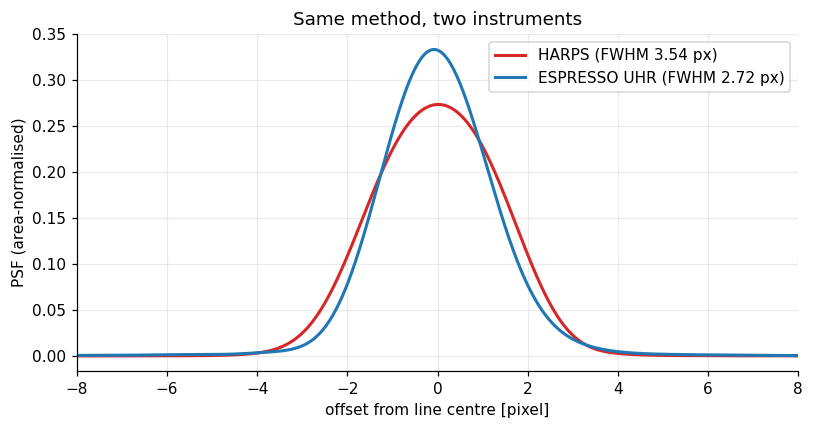

In [6]:
hp = pickle.load(open(DATA / "harps_lfc_fit_cache.pkl", "rb"))["bkg_on"]
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(hp["psf_x"], hp["psf_mean"], c="tab:red", lw=2, label=f"HARPS (FWHM {shape_stats(hp)[0]:.2f} px)")
ax.plot(good["psf_x"], good["psf_mean"], c="tab:blue", lw=2, label=f"ESPRESSO UHR (FWHM {shape_stats(good)[0]:.2f} px)")
ax.set(xlim=(-8, 8), xlabel="offset from line centre [pixel]", ylabel="PSF (area-normalised)", title="Same method, two instruments")
ax.legend(); plt.tight_layout(); plt.show()

Both were obtained with identical settings. In detector pixels the ESPRESSO PSF is a little narrower than the HARPS one, but the two instruments have different pixel scales, so this says nothing yet about physical resolution.
To compare them physically, use the RV-space routines (`compute_psf_chunk_rv`), which need each instrument's wavelength solution.

## 6. Background (chunk 1)

As for HARPS, the raw flux sits on a (small, here) background.

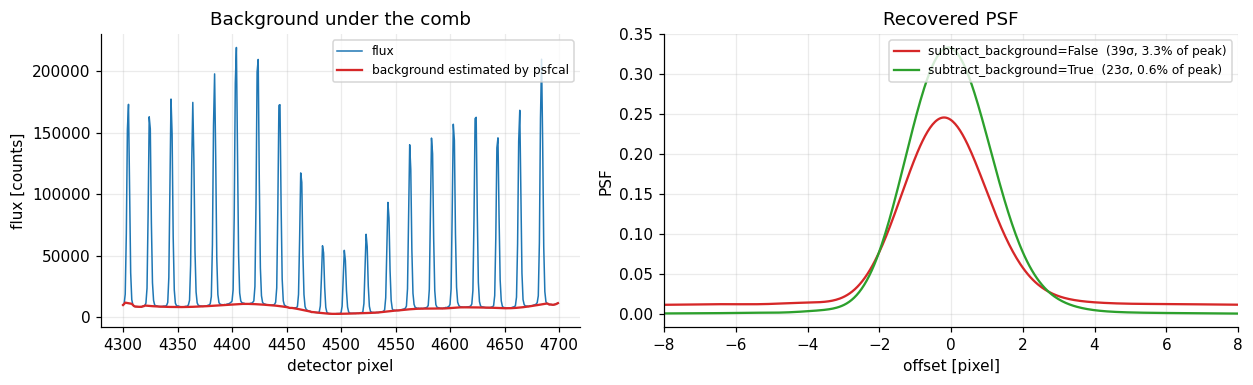

In [7]:
off = fits_["c1_bkg_off"]
f_on, s_on, rel_on = shape_stats(good)
f_off, s_off, rel_off = shape_stats(off)
fig, (a, b) = plt.subplots(1, 2, figsize=(11.5, 3.6), gridspec_kw=dict(width_ratios=[1, 1.2]))
a.plot(X[1], FLUX[1], lw=1, label="flux"); a.plot(X[1], good["background"], c="tab:red", label="background estimated by psfcal")
a.set(xlabel="detector pixel", ylabel="flux [counts]", title="Background under the comb"); a.legend(fontsize=8)
b.plot(off["psf_x"], off["psf_mean"], c="tab:red", label=f"subtract_background=False  ({off['rms']:.0f}σ, {rel_off:.1f}% of peak)")
b.plot(good["psf_x"], good["psf_mean"], c="tab:green", label=f"subtract_background=True  ({good['rms']:.0f}σ, {rel_on:.1f}% of peak)")
b.set(xlim=(-8, 8), xlabel="offset [pixel]", ylabel="PSF", title="Recovered PSF"); b.legend(fontsize=8)
plt.tight_layout(); plt.show()

The background is only ~5% of the line peaks, yet leaving it in lowers the recovered PSF peak by about a quarter, lifts the wings and introduces a spurious asymmetry (skewness from ≈0 to ≈+0.2): at this S/N small backgrounds matter.
Keep `subtract_background=True` for real spectra.

## 7. Deconvolve the chunk with its own PSF

As in the HARPS notebook: subtract the background, scale the flux to order 1 (`l2_damp` acts on the flux in its own units), and run Richardson–Lucy.

median line FWHM: observed 2.87 px → deconvolved 1.43 px  (16 lines)


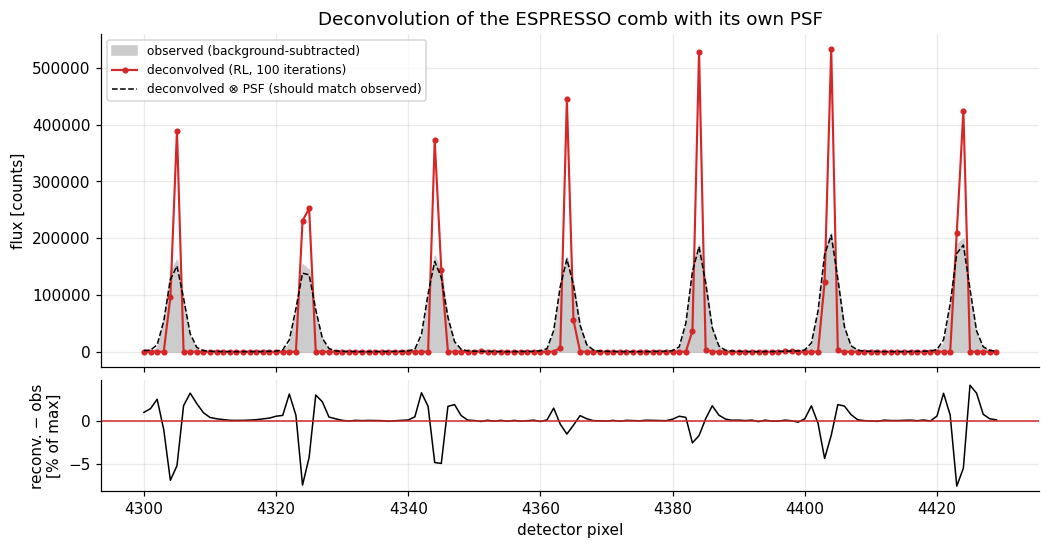

In [8]:
spec = FLUX[1] - good["background"]
scale = spec.max()
deconv = scale * psfcal.deconvolve_chunk_pixel(spec / scale, good["psf_x"], good["psf_mean"], pixel_radius=10,
                                               rl_iters=100, overlap_pix=10, continuum_normalize=False)
back = psfcal.convolve_chunk_pixel(deconv, good["psf_x"], good["psf_mean"], pixel_radius=10)

def median_fwhm(y):
    pk, _ = find_peaks(y, height=0.4 * y.max(), distance=10)
    out = []
    for p in pk:
        if p < 8 or p > len(y) - 9: continue
        h = y[p] / 2
        l = p
        while l > 0 and y[l] > h: l -= 1
        r = p
        while r < len(y) - 1 and y[r] > h: r += 1
        xl = l + (h - y[l]) / (y[l + 1] - y[l]); xr = r - 1 + (h - y[r - 1]) / (y[r] - y[r - 1])
        out.append(xr - xl)
    return np.median(out), len(out)

fo, n = median_fwhm(spec); fd, _ = median_fwhm(deconv)
print(f"median line FWHM: observed {fo:.2f} px → deconvolved {fd:.2f} px  ({n} lines)")

x = X[1]; sl = slice(0, 130)
fig, (a, b) = plt.subplots(2, 1, figsize=(11, 5.4), sharex=True, gridspec_kw=dict(height_ratios=[3, 1], hspace=0.06))
a.fill_between(x[sl], spec[sl], color="0.8", label="observed (background-subtracted)")
a.plot(x[sl], deconv[sl], c="tab:red", lw=1.4, marker="o", ms=3, label="deconvolved (RL, 100 iterations)")
a.plot(x[sl], back[sl], "k--", lw=1, label="deconvolved ⊗ PSF (should match observed)")
a.set(ylabel="flux [counts]", title="Deconvolution of the ESPRESSO comb with its own PSF"); a.legend(fontsize=8)
b.plot(x[sl], (back - spec)[sl] / np.abs(spec).max() * 100, c="k", lw=1)
b.axhline(0, c="tab:red", lw=1); b.set(xlabel="detector pixel", ylabel="reconv. − obs\n[% of max]")
plt.show()

The line FWHM drops from ≈2.9 to ≈1.4 pixels. The re-convolved spectrum (dashed) follows the observation to within ≈7% of the maximum flux, with the largest differences at the line peaks (bottom panel).

## Next steps

* **A whole exposure:** `psfcal.compute_psf_cube_pixel(flux, err, orders_1based=..., n_chunks=...)` repeats this for every chunk of every spectral row.
  ESPRESSO S2D files have **170 rows (85 orders × 2 slices)** of 9111 pixels: treat each row as an order, and pick `n_chunks` so that a chunk holds a few tens of comb lines (with ~20-pixel line spacing, ~400-pixel chunks, i.e. `n_chunks=22`).
* **Velocity space:** `compute_psf_chunk_rv` / `compute_psf_cube_rv` take the wavelength solution and the comb wavelengths (`generate_lfc_wavelengths`) so the PSFs of different instruments can be compared in km/s.
* The LFC here is on fibre A. Faint rows (very blue/red edge orders, e.g. row 40) are noise-dominated and should be skipped (psfcal flags chunks that fail in `cube["ok"]`).